# ERA5-Land daily air temperature and soil moisture EDA

Explore daily ERA5-Land estimates over Kalimantan for **2020-01-01 through 2024-12-31**. Mahdiyasa et al. (2026) specify ERA5-Land at daily resolution but not the exact bands, soil layer, daily statistic, or time zone. For a reproducible reconstruction, we chose:

| Predictor | Earth Engine band | Interpretation | Native unit |
|---|---|---|---|
| Air temperature | `temperature_2m` | Mean of hourly 2 m temperatures for each UTC day | K |
| Soil moisture | `volumetric_soil_water_layer_1` | Mean of hourly modeled soil water in the 0–7 cm layer | m³/m³ |

[Official Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR) · [Copernicus ERA5-Land daily statistics](https://cds.climate.copernicus.eu/datasets/derived-era5-land-daily-statistics)

Download with `.venv/bin/python scripts/download_era5_land_daily.py --project kalimantan-peat`. The files in `data/interim/era5_land_daily/` retain the source 0.1° grid. They have **not** been resampled to the paper's 5 × 5 km analysis grid or clipped to peatland. ERA5-Land soil water is a model estimate, not a direct measurement of peat moisture.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import shape
from shapely.plotting import plot_polygon

## 1. Load data and check time/grid coverage

Annual files contain temperature in kelvin and soil water as a volume fraction. Converting kelvin to Celsius below is for interpretation; the stored source values remain unchanged.

In [2]:
data_dir = Path("data/interim/era5_land_daily")
manifest = json.loads((data_dir / "manifest.json").read_text())
annual = {}
for year in range(2020, 2025):
    with np.load(data_dir / f"era5_land_kalimantan_{year}.npz") as data:
        annual[year] = {
            "temperature_K": data["temperature_2m_K"],
            "soil_water": data["soil_water_layer1_fraction"],
            "dates": pd.to_datetime(data["dates"]),
        }
        if year == 2020:
            latitude, longitude = data["latitude"], data["longitude"]
        else:
            assert np.array_equal(latitude, data["latitude"])
            assert np.array_equal(longitude, data["longitude"])

print("Source:", manifest["source"])
print("Grid:", len(latitude), "rows ×", len(longitude), "columns")
print("Native step:", round(abs(np.diff(latitude).mean()), 5), "degrees latitude ×",
      round(np.diff(longitude).mean(), 5), "degrees longitude")
print("Years:", {year: len(item["dates"]) for year, item in annual.items()})

Source: ERA5-Land Daily Aggregated, ECMWF, via Google Earth Engine
Grid: 96 rows × 111 columns
Native step: 0.1 degrees latitude × 0.1 degrees longitude
Years: {2020: 366, 2021: 365, 2022: 365, 2023: 365, 2024: 366}


In [3]:
dates = pd.DatetimeIndex(np.concatenate([annual[y]["dates"].values for y in annual]))
expected = pd.date_range("2020-01-01", "2024-12-31", freq="D")
print(f"Days present: {len(dates):,} / {len(expected):,}")
print("Missing dates:", len(expected.difference(dates)))
print("Duplicate dates:", dates.duplicated().sum())
assert dates.equals(expected), "ERA5-Land date coverage differs from the study period"

Days present: 1,827 / 1,827
Missing dates: 0
Duplicate dates: 0


## 2. Mask to the five provinces for descriptive summaries

The downloaded rectangle includes ocean and neighboring countries. This mask selects native pixels whose centers lie in BIG's five Kalimantan province polygons. It is **not** the final peatland mask.

In [4]:
with Path("data/raw/boundaries/big_kalimantan_provinces.geojson").open(encoding="utf-8") as file:
    province_geojson = json.load(file)

def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

provinces = [(feature["properties"]["WADMPR"], shape({
    "type": feature["geometry"]["type"],
    "coordinates": keep_xy(feature["geometry"]["coordinates"]),
})) for feature in province_geojson["features"]]
province_union = shapely.union_all([geometry for _, geometry in provinces])
lon_grid, lat_grid = np.meshgrid(longitude, latitude)
province_mask = shapely.contains_xy(province_union, lon_grid, lat_grid)
print(f"Native pixel centers inside five provinces: {province_mask.sum():,}")

Native pixel centers inside five provinces: 4,343


## 3. Quality and units

Temperature is converted to Celsius (`K − 273.15`) only after loading. Soil water is a **fraction**, so 0.4 means 40% of the soil volume in the modeled top layer. We check missingness and basic physical ranges inside Kalimantan.

In [5]:
def mean_over_days(values):
    valid_count = np.isfinite(values).sum(axis=0)
    return np.divide(np.nansum(values, axis=0), valid_count,
                     out=np.full(values.shape[1:], np.nan, dtype=np.float32),
                     where=valid_count > 0)

quality_rows = []
daily_rows = []
annual_temperature_maps = []
annual_soil_maps = []
for year, item in annual.items():
    temperature_C = item["temperature_K"] - 273.15
    soil_water = item["soil_water"]
    temp_pixels = temperature_C[:, province_mask]
    soil_pixels = soil_water[:, province_mask]
    quality_rows.append({
        "year": year,
        "days": len(item["dates"]),
        "temp_missing_pct": 100 * np.isnan(temp_pixels).mean(),
        "soil_missing_pct": 100 * np.isnan(soil_pixels).mean(),
        "all_missing_province_cells": int(np.isnan(temp_pixels).all(axis=0).sum()),
        "temp_min_C": np.nanmin(temp_pixels),
        "temp_max_C": np.nanmax(temp_pixels),
        "soil_min_fraction": np.nanmin(soil_pixels),
        "soil_max_fraction": np.nanmax(soil_pixels),
        "soil_outside_0_1": int(np.sum((soil_pixels < 0) | (soil_pixels > 1))),
    })
    daily_rows.append(pd.DataFrame({
        "date": item["dates"],
        "temperature_C": np.nanmean(temp_pixels, axis=1),
        "soil_water_fraction": np.nanmean(soil_pixels, axis=1),
    }))
    annual_temperature_maps.append(mean_over_days(temperature_C))
    annual_soil_maps.append(mean_over_days(soil_water))
quality = pd.DataFrame(quality_rows).set_index("year")
daily = pd.concat(daily_rows, ignore_index=True).set_index("date")
quality.round(3)

,days,temp_missing_pct,soil_missing_pct,all_missing_province_cells,temp_min_C,temp_max_C,soil_min_fraction,soil_max_fraction,soil_outside_0_1
year,,,,,,,,,
2020,366,1.036,1.036,45,17.136000,29.719000,0.073,0.603,0
2021,365,1.036,1.036,45,16.478001,29.809000,0.061,0.607,0
2022,365,1.036,1.036,45,15.846000,29.653999,0.112,0.604,0
2023,365,1.036,1.036,45,16.861000,31.822001,0.043,0.605,0
2024,366,1.036,1.036,45,17.302000,30.990999,0.055,0.604,0


## 4. Daily and seasonal patterns

The lines show spatial means over the five provinces, not values for an individual peatland cell. Monthly means help reveal seasonal changes without changing the stored daily data.
Cells missing on every day stay missing in the maps. They are not assigned a zero value.


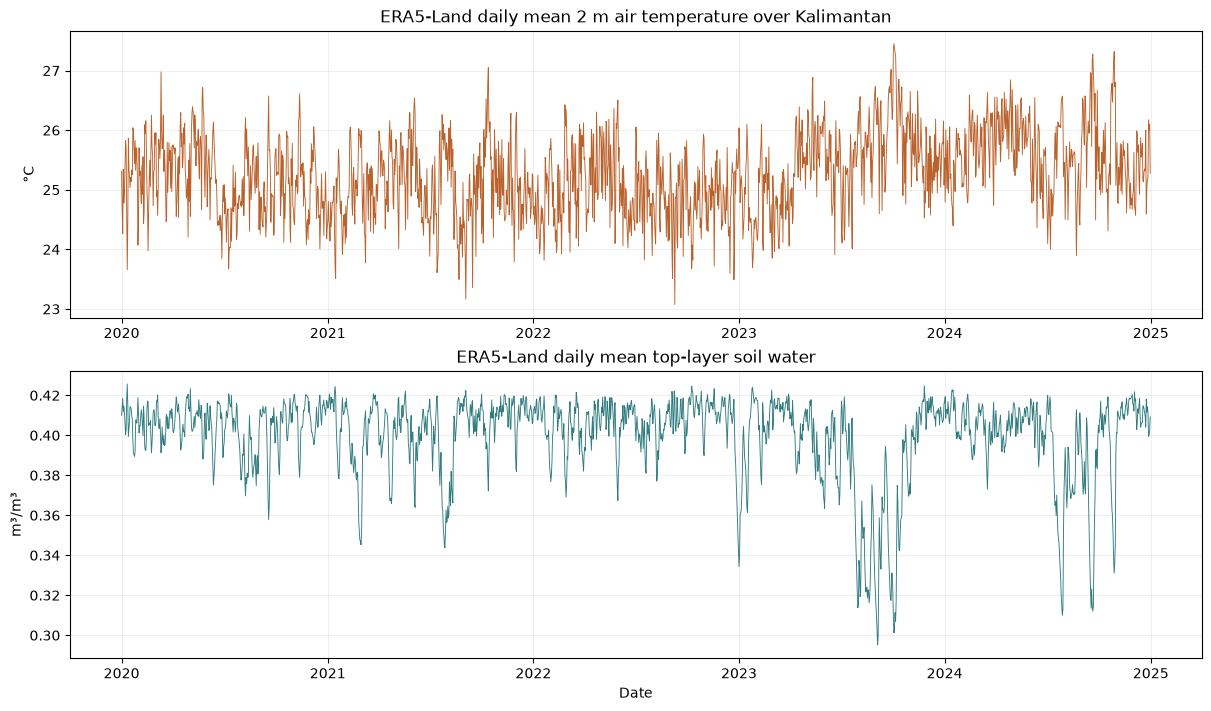

In [6]:
monthly = daily.resample("MS").mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(daily.index, daily.temperature_C, color="#bb622c", linewidth=0.65)
axes[0].set(title="ERA5-Land daily mean 2 m air temperature over Kalimantan", ylabel="°C")
axes[1].plot(daily.index, daily.soil_water_fraction, color="#307c80", linewidth=0.65)
axes[1].set(title="ERA5-Land daily mean top-layer soil water", ylabel="m³/m³", xlabel="Date")
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

In [7]:
month_profile = monthly.groupby(monthly.index.month).agg(["mean", "min", "max"])
month_profile.index.name = "month"
month_profile.round(3)

temperature_C                       soil_water_fraction              
               mean        min        max                mean    min    max
month                                                                      
1         24.952000  24.636000  25.406000               0.405  0.392  0.410
2         25.193001  24.937000  25.648001               0.401  0.388  0.405
3         25.224001  24.667000  25.806000               0.406  0.402  0.414
4         25.516001  25.270000  26.117001               0.402  0.395  0.409
5         25.691999  25.405001  25.952999               0.405  0.394  0.409
6         25.131001  24.721001  25.466999               0.401  0.390  0.409
7         25.045000  24.608999  25.406000               0.390  0.371  0.406
8         25.209000  24.827000  25.834000               0.382  0.337  0.403
9         25.346001  24.798000  26.176001               0.386  0.344  0.410
10        25.495001  24.767000  26.274000               0.395  0.360  0.413
11        25.165001  24.934000  25.636999               0.411  0.405  0.413
12        25.125999  24.839001  25.417000               0.409  0.402  0.412

## 5. Spatial patterns

These are five-year means on the native 0.1° grid. A 5 × 5 km model grid will contain cells smaller than the native ERA5-Land pixels; later resampling cannot create new local climate detail.

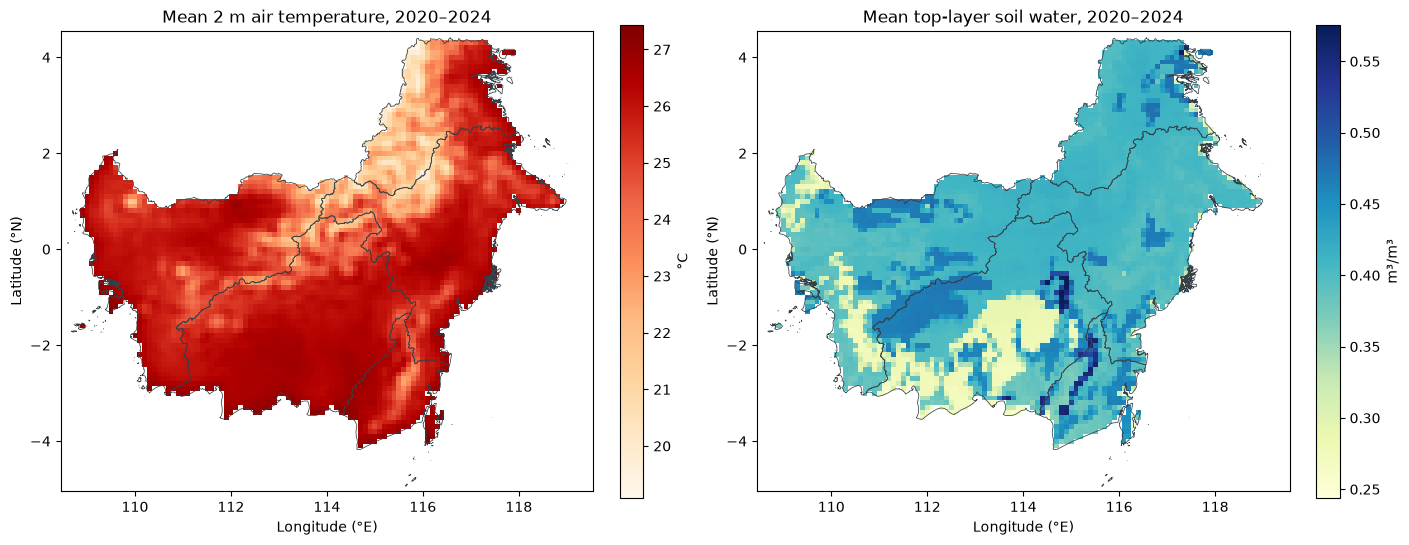

In [8]:
mean_temperature_C = np.mean(annual_temperature_maps, axis=0)
mean_soil_water = np.mean(annual_soil_maps, axis=0)
step_lon = np.diff(longitude).mean()
step_lat = abs(np.diff(latitude).mean())
extent = [longitude.min()-step_lon/2, longitude.max()+step_lon/2,
          latitude.min()-step_lat/2, latitude.max()+step_lat/2]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, values, cmap, title, label in [
    (axes[0], mean_temperature_C, "OrRd", "Mean 2 m air temperature, 2020–2024", "°C"),
    (axes[1], mean_soil_water, "YlGnBu", "Mean top-layer soil water, 2020–2024", "m³/m³"),
]:
    image = np.ma.masked_where(~province_mask, values)
    im = ax.imshow(image, origin="upper", extent=extent, cmap=cmap, interpolation="nearest")
    for _, geom in provinces:
        plot_polygon(geom.simplify(0.003, preserve_topology=True), ax=ax,
                     add_points=False, facecolor="none", edgecolor="#354049", linewidth=0.55)
    ax.set(title=title, xlabel="Longitude (°E)", ylabel="Latitude (°N)")
    ax.set_aspect("equal", adjustable="box")
    fig.colorbar(im, ax=ax, shrink=0.8, label=label)
plt.show()

## Interpretation before preprocessing

- These are daily **UTC** means. The paper does not specify whether its daily data use UTC or local Indonesian time; changing the day boundary would require recomputing from hourly data.
- We chose 2 m air temperature and 0–7 cm soil water because the paper does not name exact ERA5-Land bands or soil depth. Record this as a reconstruction assumption.
- ERA5-Land soil water comes from a land-surface model and may not represent peat hydrology or water-table depth faithfully. It is a predictor candidate, not a peat moisture observation.
- Later, align both variables to the project-defined 5 × 5 km grid and choose predictor dates that occur before the forecast target to avoid leakage.